# Classificação de diabetes com XGBoost e MLFlow (dataset NIDDK)

<mark>Este notebook é didático e não deve ser utilizado para realizar diagnósticos</mark>

Este notebook reproduz o experimento em `02-xgboost-niddk-diabetes.ipynb` e adiciona rastreabilidade e versionamento utilizando MLflow. Ele é independente do `02`: precisa somente do Parquet produzido por `01-prepare-niddk-diabetes.ipynb`.

Este notebook utiliza os dados preparados por `01-prepare-niddk-diabetes.ipynb` para treinar e avaliar um único classificador binário: **XGBoost**. O fluxo é intencionalmente compacto: carregar os dados, definir `X` e `y`, separar os conjuntos, treinar o modelo e avaliar suas previsões.

## Iniciar o MLflow local

Execute em um terminal separado, partindo da raiz do repositório, e mantenha-o aberto:

Preparar o ambiente:

```powershell
cd ml
uv sync --locked
```

Testar o MLFlow:

```powershell
uv run --locked python -c "from pathlib import Path; Path('../outputs/mlflow').mkdir(parents=True, exist_ok=True)"
```

Rodar o servidor MLFlow:

```powershell
uv run --locked mlflow server --host 127.0.0.1 --port 5000 --backend-store-uri sqlite:///../outputs/mlflow/mlflow.db --artifacts-destination ../outputs/mlflow/artifacts
```

Abra o MLFlow server em http://127.0.0.1:5000. O SQLite guarda experimentos, execuções e versões; os artefatos guardam o modelo e os relatórios. Ambos ficam em `outputs/`, ignorada pelo Git. Se o servidor não estiver acessível, a verificação abaixo interrompe o fluxo antes de treinar.

## Importações e caminhos do projeto

### Bibliotecas

Usamos `mlflow.sklearn.autolog()` para acompanhar o treinamento do pipeline: ele registra automaticamente parâmetros do estimador, métricas de treino, dataset de treino, modelo, assinatura e exemplo de entrada. As métricas de teste e os artefatos específicos do projeto continuam explícitos.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import platform

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display
from mlflow import MlflowClient
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")


def find_project_root() -> Path:
    """Retorna a raiz do repositório quando o notebook é executado neste projeto."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "ml" / "pyproject.toml").is_file() and (
            candidate / "README.md"
        ).is_file():
            return candidate
    raise FileNotFoundError("Abra este notebook dentro do repositório do projeto.")

c:\Users\lenin\Projects\ufabc\ufabc-DiabetesMellitusPrediction\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Variáveis

In [2]:
PROJECT_ROOT = find_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "niddk-diabetes" / "diabetes.parquet"
TARGET_COLUMN = "diabetes"
IDENTIFIER_COLUMN = "id_paciente"

RANDOM_STATE = 42
TEST_SIZE = 0.20
TRACKING_URI = "http://127.0.0.1:5000"
EXPERIMENT_NAME = "niddk-diabetes-xgboost"
REGISTERED_MODEL_NAME = "niddk-diabetes-xgboost"

MODEL_PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}
NOTEBOOK_NAME = "03-mlflow-niddk-diabetes.ipynb"


## Conectar ao servidor e definir o experimento

Um **experimento** reúne execuções comparáveis. Cada **run** representa uma execução de treinamento e avaliação. O **Model Registry** mantém versões do modelo registrado.

In [3]:
try:
    response = requests.get(f"{TRACKING_URI}/health", timeout=5)
    response.raise_for_status()
except requests.RequestException as exc:
    raise RuntimeError(
        "MLflow local indisponível. Inicie o servidor conforme a seção 1 e execute esta célula novamente."
    ) from exc

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_registry_uri(TRACKING_URI)

experiment = mlflow.set_experiment(EXPERIMENT_NAME)

print(f"MLflow: {mlflow.get_tracking_uri()}")
print(f"Experimento: {EXPERIMENT_NAME} (ID {experiment.experiment_id})")

2026/10/26 21:28:53 INFO mlflow.tracking.fluent: Experiment with name 'niddk-diabetes-xgboost' does not exist. Creating a new experiment.


MLflow: http://127.0.0.1:5000
Experimento: niddk-diabetes-xgboost (ID 1)


## Carregar o dataset preparado

O notebook de preparação traduz as colunas de origem para português e as salva em Parquet. Antes de prosseguir, verificamos se as colunas de alvo e identificador esperadas estão presentes.

In [4]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset preparado não encontrado em {DATA_PATH}. "
        "Execute primeiro 01-prepare-niddk-diabetes.ipynb."
    )

data = pd.read_parquet(DATA_PATH)
required_columns = {TARGET_COLUMN, IDENTIFIER_COLUMN}
missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f"O dataset não possui as colunas obrigatórias: {sorted(missing_columns)}")

print(f"Dimensões do dataset: {data.shape}")

Dimensões do dataset: (10000, 10)


In [5]:
print(f"Distribuição das classes:\n{data[TARGET_COLUMN].value_counts(normalize=True).sort_index()}")

Distribuição das classes:
diabetes
0    0.6656
1    0.3344
Name: proportion, dtype: float64


In [6]:
display(data.head())

,id_paciente,gestacoes,glicose_plasmatica,pressao_arterial_diastolica,espessura_triceps,insulina_serica,imc,indice_hereditariedade_diabetes,idade,diabetes
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0


## Separar os conjuntos em variáveis de entrada `X` e alvo `y`

`diabetes` é o desfecho binário a ser previsto. `id_paciente` é removida porque identifica um registro em vez de descrever uma característica da pessoa, as demais colunas formam `X`.

In [7]:
feature_columns = [
    column for column in data.columns if column not in {TARGET_COLUMN, IDENTIFIER_COLUMN}
]

X = data[feature_columns]
y = data[TARGET_COLUMN]

print(f"Dimensões de X: {X.shape}")
print(f"Dimensões de y: {y.shape}")
print(f"Variáveis de entrada: {feature_columns}")

Dimensões de X: (10000, 8)
Dimensões de y: (10000,)
Variáveis de entrada: ['gestacoes', 'glicose_plasmatica', 'pressao_arterial_diastolica', 'espessura_triceps', 'insulina_serica', 'imc', 'indice_hereditariedade_diabetes', 'idade']


## Criar os conjuntos de treino e teste

O conjunto de teste fica reservado até a avaliação. `stratify=y` preserva a proporção das classes em ambas as divisões, e `random_state` torna o resultado reproduzível.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Conjunto de treino: {X_train.shape[0]} linhas")
print(f"Conjunto de teste:  {X_test.shape[0]} linhas")
print(f"Variáveis:          {X_train.shape[1]}")

Conjunto de treino: 8000 linhas
Conjunto de teste:  2000 linhas
Variáveis:          8


## Treinar, avaliar e registrar uma execução

Ativamos `mlflow.sklearn.autolog()` antes de `pipeline.fit(...)`. O autolog detecta o treinamento e registra os parâmetros do pipeline, métricas de treino, dados de treino, modelo, assinatura e exemplo de entrada. `registered_model_name` também cria uma versão no Model Registry.

O bloco `with mlflow.start_run(...)` agrupa os registros e finaliza o status da execução, inclusive em caso de erro.

Mantemos explícitos apenas os registros específicos deste experimento:

- Divisão treino/teste, semente e limiar de classificação.
- Métricas de teste com prefixo `test_`: acurácia, precisão, revocação, F1 e ROC-AUC.
- Matriz de confusão, importância global e relatório de classificação.
- Hash do Parquet, contrato das entradas, índices da divisão, notebook e lockfile.

`log_post_training_metrics=False` evita métricas duplicadas calculadas fora do treinamento. As métricas automáticas de treino continuam ativas; não devem ser confundidas com as métricas de teste.

O pipeline tem uma etapa porque não há transformação numérica neste experimento. Sua entrada é um DataFrame com os atributos em português **sem** identificador e alvo. Usamos o autolog de scikit-learn para preservar o pipeline completo com XGBoost, inclusive se acrescentarmos pré-processamento posteriormente.

**Reexecutar esta célula cria outra run e outra versão registrada.** Registrar uma versão não altera automaticamente a API.

A serialização é `cloudpickle`. A recarga abaixo usa somente o artefato que acabamos de treinar e registrar localmente.

2026/10/26 21:29:20 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\lenin\Projects\ufabc\ufabc-DiabetesMellitusPrediction\ml\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/26 21:29:20 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users

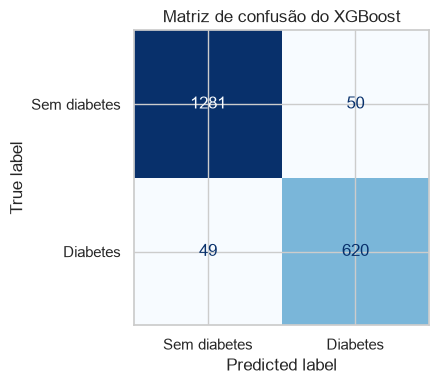

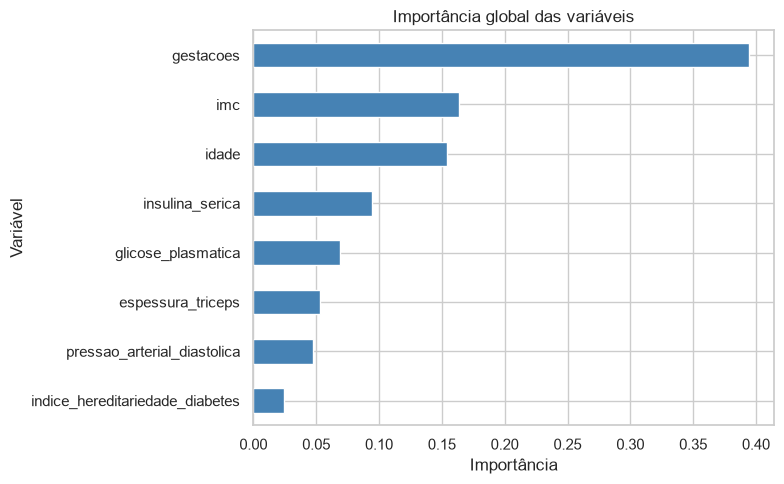

🏃 View run xgboost-baseline at: http://127.0.0.1:5000/#/experiments/1/runs/43e529856497466f9fd145b75b010135
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Run finalizada: 43e529856497466f9fd145b75b010135


,métrica
test_accuracy,0.9505
test_precision,0.9254
test_recall,0.9268
test_f1,0.9261
test_roc_auc,0.9902


              precision    recall  f1-score   support

           0      0.963     0.962     0.963      1331
           1      0.925     0.927     0.926       669

    accuracy                          0.951      2000
   macro avg      0.944     0.945     0.944      2000
weighted avg      0.951     0.951     0.951      2000



In [9]:
if mlflow.active_run() is not None:
    raise RuntimeError(
        "Há uma run ativa neste kernel. Finalize-a antes de iniciar este experimento."
    )

# Calculado nesta célula para permitir repetir o registro sem depender do estado anterior do kernel.
dataset_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

# O autolog acompanha Pipeline.fit e registra o pipeline completo.
# As métricas de teste permanecem explícitas para usar nomes estáveis.
mlflow.sklearn.autolog(
    log_input_examples=True,
    log_model_signatures=True,
    log_models=True,
    log_datasets=True,
    log_post_training_metrics=False,
    serialization_format="cloudpickle",
    registered_model_name=REGISTERED_MODEL_NAME,
    pos_label=1,
)

pipeline = Pipeline([("classifier", XGBClassifier(**MODEL_PARAMS))])

with mlflow.start_run(run_name="xgboost-baseline") as run:
    run_id = run.info.run_id
    mlflow.set_tags(
        {
            "dataset": "niddk-diabetes",
            "notebook": NOTEBOOK_NAME,
            "purpose": "didatico",
            "dataset_sha256": dataset_sha256,
            "python_version": platform.python_version(),
        }
    )
    mlflow.log_params(
        {
            "test_size": TEST_SIZE,
            "split_random_state": RANDOM_STATE,
            "stratified": True,
            "decision_threshold": 0.5,
            "train_rows": len(X_train),
            "test_rows": len(X_test),
            "feature_count": len(feature_columns),
        }
    )

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_probability = pipeline.predict_proba(X_test)[:, 1]
    metrics = {
        "test_accuracy": accuracy_score(y_test, y_pred),
        "test_precision": precision_score(y_test, y_pred, zero_division=0),
        "test_recall": recall_score(y_test, y_pred, zero_division=0),
        "test_f1": f1_score(y_test, y_pred, zero_division=0),
        "test_roc_auc": roc_auc_score(y_test, y_probability),
    }
    mlflow.log_metrics(metrics)
    mlflow.log_dict(
        classification_report(y_test, y_pred, output_dict=True, zero_division=0),
        "reports/classification_report.json",
    )
    mlflow.log_dict(
        {
            "columns": [
                {"name": column, "dtype": str(X[column].dtype)}
                for column in feature_columns
            ],
            "target": TARGET_COLUMN,
            "excluded_identifier": IDENTIFIER_COLUMN,
            "class_labels": {"0": "Sem diabetes", "1": "Diabetes"},
            "decision_threshold": 0.5,
        },
        "metadata/input_contract.json",
    )
    mlflow.log_dict(
        {
            "parquet_path": str(DATA_PATH.relative_to(PROJECT_ROOT)),
            "parquet_sha256": dataset_sha256,
            "rows": len(data),
            "source_page": "https://github.com/MicrosoftLearning/AI-900-AIFundamentals/blob/main/data/ml/diabetes.csv",
            "provenance_note": "Distribuído pela Microsoft; atribuição dos dados de base ao NIDDK. Transformações não identificadas.",
        },
        "metadata/dataset.json",
    )
    mlflow.log_dict(
        {"train_index": X_train.index.tolist(), "test_index": X_test.index.tolist()},
        "metadata/split_indices.json",
    )
    mlflow.log_dict(
        {
            package: version(package)
            for package in ("mlflow", "xgboost", "scikit-learn", "pandas", "numpy")
        },
        "metadata/versions.json",
    )
    lockfile = PROJECT_ROOT / "ml" / "uv.lock"
    if lockfile.is_file():
        mlflow.log_artifact(str(lockfile), artifact_path="metadata")

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Sem diabetes", "Diabetes"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title("Matriz de confusão do XGBoost")
    fig.tight_layout()
    mlflow.log_figure(fig, "plots/confusion_matrix.png")
    plt.show()
    plt.close(fig)

    feature_importance = pd.Series(
        pipeline.named_steps["classifier"].feature_importances_,
        index=feature_columns,
    ).sort_values()
    fig, ax = plt.subplots(figsize=(8, 5))
    feature_importance.plot.barh(ax=ax, color="steelblue")
    ax.set(
        title="Importância global das variáveis",
        xlabel="Importância",
        ylabel="Variável",
    )
    fig.tight_layout()
    mlflow.log_figure(fig, "plots/feature_importance.png")
    plt.show()
    plt.close(fig)

    notebook_path = (
        PROJECT_ROOT / "ml" / "notebooks" / NOTEBOOK_NAME
    )
    mlflow.log_artifact(str(notebook_path), artifact_path="metadata")


print(f"Run finalizada: {run_id}")
display(pd.Series(metrics, name="métrica").to_frame().round(4))
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

## Consultar a versão registrada

O nome registrado agrupa versões; a URI abaixo fixa exatamente a versão desta execução.

Como `autolog()` não retorna um `ModelInfo`, buscamos a versão cujo `run_id` corresponde à execução atual, sem escolher simplesmente a versão mais recente.

In [10]:
client = MlflowClient()

# O autolog não retorna ModelInfo: localizamos a versão pela run atual.
versions = client.search_model_versions(f"name='{REGISTERED_MODEL_NAME}'")
matching_versions = [item for item in versions if item.run_id == run_id]
if len(matching_versions) != 1:
    raise RuntimeError(
        "Era esperada uma versão criada pelo autolog nesta run. "
        "Confira os avisos da célula de treinamento e o Model Registry."
    )
registered_version = matching_versions[0]
model_version = str(registered_version.version)
if registered_version.run_id != run_id:
    raise RuntimeError("A versão registrada não corresponde à run deste treinamento.")

MODEL_URI = f"models:/{REGISTERED_MODEL_NAME}/{model_version}"

print(f"Nome: {REGISTERED_MODEL_NAME}")
print(f"Versão: {model_version}; status: {registered_version.status}")
print(f"URI para carregar: {MODEL_URI}")
print(
    f"Execução: {TRACKING_URI}/#/experiments/{experiment.experiment_id}/runs/{run_id}"
)

Nome: niddk-diabetes-xgboost
Versão: 1; status: READY
URI para carregar: models:/niddk-diabetes-xgboost/1
Execução: http://127.0.0.1:5000/#/experiments/1/runs/43e529856497466f9fd145b75b010135


## Recarregar pelo MLflow e verificar a inferência

O artefato é baixado para `outputs/models/`, criada automaticamente. Conferimos classes e probabilidades para todo o teste, verificando que o modelo recarregado reproduz o modelo em memória. Usamos o flavor scikit-learn para preservar `predict_proba`.

In [11]:
DOWNLOAD_DIR = PROJECT_ROOT / "outputs" / "models"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

loaded_pipeline = mlflow.sklearn.load_model(MODEL_URI, dst_path=str(DOWNLOAD_DIR))

np.testing.assert_array_equal(loaded_pipeline.predict(X_test), y_pred)
np.testing.assert_allclose(
    loaded_pipeline.predict_proba(X_test)[:, 1],
    y_probability,
    rtol=1e-6,
    atol=1e-8,
)

example = X_test.head(3)

display(example)

display(
    pd.DataFrame(
        {
            "classe_prevista": loaded_pipeline.predict(example),
            "probabilidade_classe_1": loaded_pipeline.predict_proba(example)[:, 1],
        },
        index=example.index,
    )
)

print("Modelo registrado e recarregado: previsões e probabilidades conferidas.")

,gestacoes,glicose_plasmatica,pressao_arterial_diastolica,espessura_triceps,insulina_serica,imc,indice_hereditariedade_diabetes,idade
8500,9,119,73,26,203,28.494795,0.473327,21
9029,0,163,85,43,264,19.248474,0.666872,21
9944,3,138,59,31,476,43.157617,0.081793,23


,classe_prevista,probabilidade_classe_1
8500,1,0.944047
9029,0,0.009172
9944,1,0.658123


Modelo registrado e recarregado: previsões e probabilidades conferidas.
